### visualization on continuous columns

In [54]:
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [55]:
finance_df = pd.read_excel(r"E:\Data SCience\finance_scaling_selection.xlsx")

In [56]:
finance_df

,Unnamed: 0,customer_id,policy_id,age_years,annual_income,monthly_income,credit_score,credit_band,region,employment_type,...,payment_method,autopay_enabled,risk_segment,vehicle_age_years,vehicle_value,property_value,policy_start_month,credit_enquiries_6m,policy_changes_3y,annual_claim_amount
0,0,CUST_000001,POL_000001,56,124665.90,10388.82,664,Fair,North,Retired,...,Auto-Debit,1,Low,6,18845.45,556132.42,11,0,0,1682.17
1,1,CUST_000002,POL_000002,69,206552.68,17212.72,679,Good,West,Salaried,...,Net Banking,1,Low,1,36621.06,923515.67,11,1,0,1801.33
2,2,CUST_000003,POL_000003,46,101110.63,8425.89,647,Fair,Central,Salaried,...,Auto-Debit,1,Medium,2,33408.98,457255.01,8,4,1,2824.43
3,3,CUST_000004,POL_000004,32,56500.52,4708.38,616,Fair,East,Business Owner,...,Net Banking,0,High,4,24848.71,186069.04,1,1,1,1732.87
4,4,CUST_000005,POL_000005,60,161781.92,13481.83,784,Very Good,East,Salaried,...,Auto-Debit,1,Low,12,8942.45,647514.91,12,0,0,2027.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,24995,CUST_024996,POL_024996,64,94224.01,7852.00,676,Good,East,Self-Employed,...,Manual Check,1,Low,4,23865.30,351242.44,7,1,0,1739.62
24996,24996,CUST_024997,POL_024997,25,42078.35,3506.53,750,Very Good,East,Business Owner,...,Auto-Debit,1,Medium,4,25054.52,151552.95,4,1,1,2322.23
24997,24997,CUST_024998,POL_024998,74,183594.97,15299.58,657,Fair,Central,Salaried,...,Credit Card,0,Medium,15,7675.70,470749.10,7,3,0,3424.71
24998,24998,CUST_024999,POL_024999,54,89411.81,7450.98,751,Very Good,West,Salaried,...,Credit Card,0,Low,15,3023.16,366618.94,5,2,0,1887.24


In [57]:
finance_df.describe()

,Unnamed: 0,age_years,annual_income,monthly_income,credit_score,dependents_count,customer_tenure_years,policy_tenure_months,annual_premium,insured_amount,...,loan_payment_monthly,monthly_expenses,autopay_enabled,vehicle_age_years,vehicle_value,property_value,policy_start_month,credit_enquiries_6m,policy_changes_3y,annual_claim_amount
count,25000.000000,25000.000000,2.500000e+04,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,...,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,2.500000e+04,25000.000000,25000.00000,25000.000000,25000.000000
mean,12499.500000,45.987920,8.756629e+04,7297.190835,679.286720,1.206040,10.214388,122.552864,2113.952798,58112.878390,...,348.736289,4185.138766,0.610720,9.503880,16058.832888,3.729966e+05,6.519320,1.00460,0.398200,2609.904655
std,7217.022701,16.437507,5.786395e+04,4821.995621,83.498075,1.098488,5.633021,67.652169,889.177421,29456.177584,...,230.530175,2896.971884,0.487597,5.763946,10838.521135,2.668641e+05,3.453929,1.00442,0.629009,1487.089102
min,0.000000,18.000000,5.017250e+03,418.100000,314.000000,0.000000,0.500000,1.000000,445.870000,10114.020000,...,3.330000,337.160000,0.000000,0.000000,1000.000000,1.876719e+04,1.000000,0.00000,0.000000,0.000000
25%,6249.750000,32.000000,4.841883e+04,4034.902500,623.000000,0.000000,5.300000,64.350000,1524.772500,38001.092500,...,185.827500,2261.540000,0.000000,5.000000,7261.377500,1.945603e+05,3.000000,0.00000,0.000000,1625.202500
50%,12499.500000,46.000000,7.322476e+04,6102.065000,680.000000,1.000000,10.200000,122.100000,1910.085000,51951.235000,...,315.035000,3423.685000,1.000000,10.000000,12928.770000,3.015021e+05,7.000000,1.00000,0.000000,2315.155000
75%,18749.250000,60.000000,1.099933e+05,9166.110000,738.000000,2.000000,15.100000,180.800000,2475.670000,70653.065000,...,472.922500,5223.395000,1.000000,14.000000,23290.387500,4.723880e+05,10.000000,2.00000,1.000000,3258.500000
max,24999.000000,74.000000,1.074591e+06,89549.240000,850.000000,6.000000,20.000000,240.000000,15000.000000,399980.660000,...,2721.560000,40578.270000,1.000000,19.000000,46972.820000,4.408937e+06,12.000000,6.00000,4.000000,16703.840000


In [58]:
finance_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 43 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Unnamed: 0                  25000 non-null  int64  
 1   customer_id                 25000 non-null  str    
 2   policy_id                   25000 non-null  str    
 3   age_years                   25000 non-null  int64  
 4   annual_income               25000 non-null  float64
 5   monthly_income              25000 non-null  float64
 6   credit_score                25000 non-null  int64  
 7   credit_band                 25000 non-null  str    
 8   region                      25000 non-null  str    
 9   employment_type             25000 non-null  str    
 10  education_level             25000 non-null  str    
 11  marital_status              25000 non-null  str    
 12  dependents_count            25000 non-null  int64  
 13  customer_tenure_years       25000 non-null

In [59]:
finance_df.columns


Index(['Unnamed: 0', 'customer_id', 'policy_id', 'age_years', 'annual_income',
       'monthly_income', 'credit_score', 'credit_band', 'region',
       'employment_type', 'education_level', 'marital_status',
       'dependents_count', 'customer_tenure_years', 'policy_tenure_months',
       'annual_premium', 'insured_amount', 'deductible_amount',
       'claim_count_3y', 'claim_amount_3y', 'last_claim_days_ago',
       'late_payments_12m', 'missed_payments_12m', 'debt_amount',
       'debt_to_income', 'savings_balance', 'bank_balance',
       'transaction_count_12m', 'average_transaction_amount',
       'credit_utilization', 'loan_count', 'loan_payment_monthly',
       'monthly_expenses', 'payment_method', 'autopay_enabled', 'risk_segment',
       'vehicle_age_years', 'vehicle_value', 'property_value',
       'policy_start_month', 'credit_enquiries_6m', 'policy_changes_3y',
       'annual_claim_amount'],
      dtype='str')

In [60]:
ss = StandardScaler()
ss_scaled = ss.fit_transform(finance_df[["age_years"]])
print(ss_scaled)

[[6.09111863e-01]
 [1.40000189e+00]
 [7.34919348e-04]
 ...
 [1.70419036e+00]
 [4.87436475e-01]
 [1.64335267e+00]]


Text(0.5, 1.0, 'Age scaling')

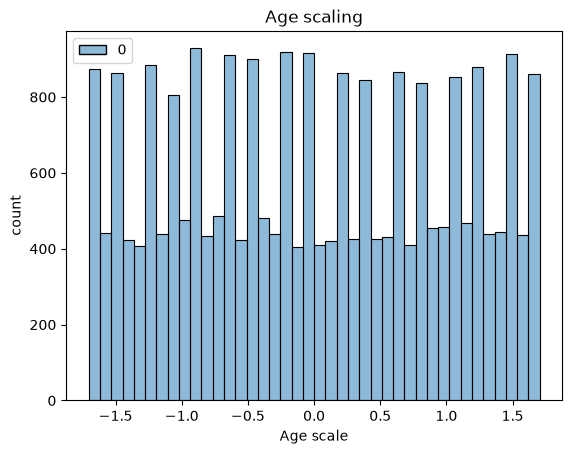

In [61]:
# scaling on ages
sns.histplot(ss_scaled, bins=40)
plt.xlabel("Age scale")
plt.ylabel("count")
plt.title(f"Age scaling")


In [62]:
ss = StandardScaler()
bal_scaled = ss.fit_transform(finance_df[["bank_balance"]])
print(bal_scaled)

[[-0.44728325]
 [-0.49164098]
 [-0.91865415]
 ...
 [ 2.60198528]
 [ 1.52981534]
 [ 0.56356402]]


Text(0.5, 1.0, 'Balance scaling')

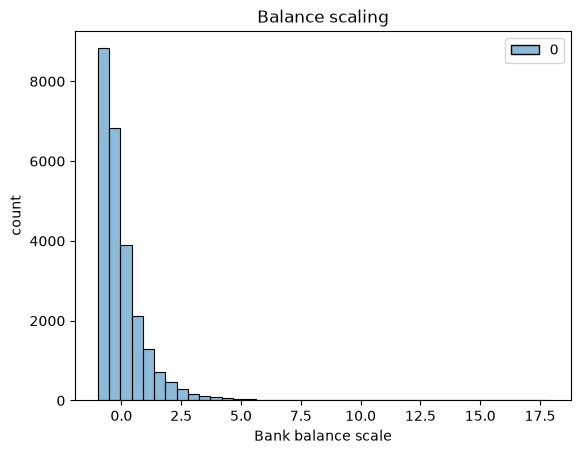

In [63]:
sns.histplot(bal_scaled, color='crimson', bins=40)
plt.xlabel("Bank balance scale")
plt.ylabel("count")
plt.title(f"Balance scaling")

In [64]:
ss = StandardScaler()
exp_scaled = ss.fit_transform(finance_df[["monthly_expenses"]])
print(exp_scaled)

[[ 0.51171739]
 [ 3.05976684]
 [ 0.36480933]
 ...
 [ 0.94767442]
 [-0.3018035 ]
 [-0.18261114]]


Text(0.5, 1.0, 'scaling on monthly expences')

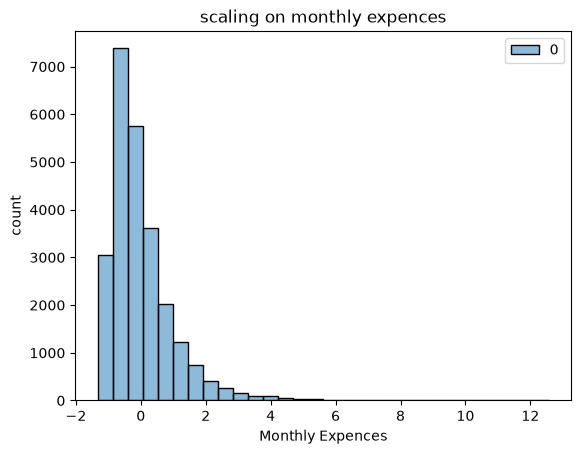

In [65]:
sns.histplot(exp_scaled, color='crimson', bins=30)
plt.xlabel("Monthly Expences")
plt.ylabel("count")
plt.title(f"scaling on monthly expences")

In [66]:
ss = StandardScaler()
ss_scaled = ss.fit_transform(finance_df[["annual_claim_amount"]])
print(ss_scaled)

[[-0.62387197]
 [-0.54374067]
 [ 0.14426145]
 ...
 [ 0.54793061]
 [-0.48596894]
 [ 0.50924352]]


Text(0.5, 1.0, 'Annual amount scaling')

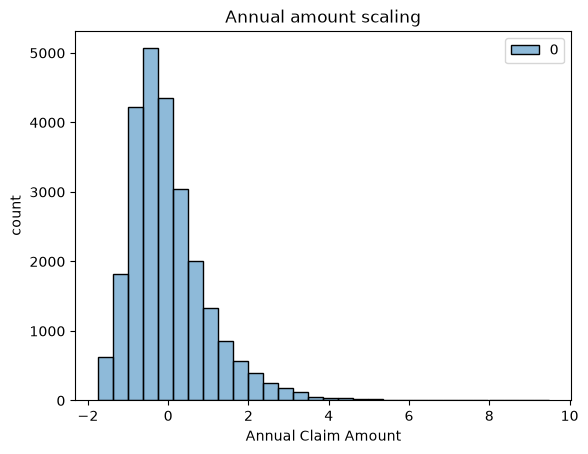

In [67]:
sns.histplot(ss_scaled, bins=30)
plt.xlabel("Annual Claim Amount")
plt.ylabel("count")
plt.title(f"Annual amount scaling")

In [68]:
ss = StandardScaler()
credit_scaled = ss.fit_transform(finance_df[["credit_utilization"]])
print(credit_scaled)

[[-1.24661271]
 [-1.31514769]
 [ 0.24184236]
 ...
 [ 0.81815921]
 [ 0.97890488]
 [ 0.58140202]]


Text(0.5, 1.0, 'credit_utilization scaling')

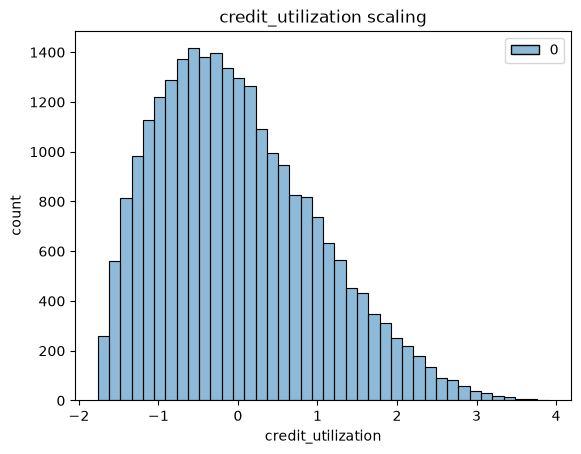

In [70]:
sns.histplot(credit_scaled, bins=40, color='red')
plt.xlabel("credit_utilization")
plt.ylabel("count")
plt.title(f"credit_utilization scaling")